# 02 - RFM Analysis and Customer Segmentation

Data source: `rpt.vw_CustomerOrders` (delivered orders only, revenue excludes freight, customer = `customer_unique_id`).

**RFM** describes each customer with three numbers:
- **Recency** - days since the last purchase (lower = better)
- **Frequency** - number of separate purchase days (higher = better)
- **Monetary** - total amount spent (higher = better)

Decisions taken from the EDA (`01_eda.ipynb`):
- Frequency counts **distinct purchase days**, not orders: 30.5% of second orders were placed on the same day as the first (split baskets), which is not a real return.
- All delivered orders are used, including 2016, because RFM describes each customer's full history.


## 1. Load orders


In [1]:
import numpy as np
import pandas as pd
from db_utils import read_view

orders = read_view("vw_CustomerOrders")
orders["purchase_date"] = pd.to_datetime(orders["purchase_date"])

print(f"Orders: {len(orders):,} | customers: {orders['customer_key'].nunique():,}")
print("Dates :", orders["purchase_date"].min().date(), "->", orders["purchase_date"].max().date())

Orders: 96,470 | customers: 93,350
Dates : 2016-09-15 -> 2018-08-29


## 2. Compute raw RFM values per customer

**Snapshot date** = the day after the last order in the data. Recency is measured from that day, as if we ran the analysis the morning after the data ends.


In [2]:
SNAPSHOT = orders["purchase_date"].max() + pd.Timedelta(days=1)
print("Snapshot date:", SNAPSHOT.date())

rfm = (orders.groupby("customer_key")
       .agg(customer_unique_id=("customer_unique_id", "first"),
            first_purchase=("purchase_date", "min"),
            last_purchase=("purchase_date", "max"),
            frequency=("purchase_date", "nunique"),   # distinct purchase DAYS
            orders=("order_id", "count"),             # kept for reference
            monetary=("revenue", "sum")))
rfm["recency_days"] = (SNAPSHOT - rfm["last_purchase"]).dt.days

# --- Checks against the reference numbers (SQL, Phase 1) ---
checks = {
    "Customers": (len(rfm), 93_350),
    "Orders":    (rfm["orders"].sum(), 96_470),
    "Revenue":   (round(rfm["monetary"].sum(), 2), 13_220_248.93),
    "Customers with 2+ orders": ((rfm["orders"] >= 2).sum(), 2_801),
}
for label, (actual, expected) in checks.items():
    print(f"{'OK' if actual == expected else 'MISMATCH':<9} {label}: {actual:,} (expected {expected:,})")

print(f"\nCustomers with 2+ purchase DAYS (real returners): {(rfm['frequency'] >= 2).sum():,} "
      f"({(rfm['frequency'] >= 2).mean():.1%})")

Snapshot date: 2018-08-30
OK        Customers: 93,350 (expected 93,350)
OK        Orders: 96,470 (expected 96,470)
OK        Revenue: 13,220,248.93 (expected 13,220,248.93)
OK        Customers with 2+ orders: 2,801 (expected 2,801)

Customers with 2+ purchase DAYS (real returners): 2,015 (2.2%)


In [3]:
# Distribution of the three RFM values
print(rfm[["recency_days", "frequency", "monetary"]].describe(percentiles=[.2, .4, .5, .6, .8]).round(1).to_string())
print()
print("Frequency (purchase days) counts:")
print(rfm["frequency"].value_counts().sort_index().to_string())

       recency_days  frequency  monetary
count       93350.0    93350.0   93350.0
mean          238.5        1.0     141.6
std           152.6        0.2     215.7
min             1.0        1.0       0.8
20%            93.0        1.0      39.9
40%           178.0        1.0      69.9
50%           220.0        1.0      89.7
60%           269.0        1.0     109.9
80%           383.0        1.0     179.9
max           714.0       15.0   13440.0

Frequency (purchase days) counts:
frequency
1     91335
2      1864
3       120
4        17
5         6
6         5
7         2
15        1


## 3. Turn raw values into 1-5 scores

- **R score** and **M score**: quintiles (5 equal-sized groups). Recent customers get R = 5; big spenders get M = 5.
- **F score**: quintiles are impossible, because ~98% of customers have exactly 1 purchase day (they would all fall in the same group). Instead we use the **actual number of purchase days**, capped at 5: 1 day = 1, 2 days = 2, ..., 5+ days = 5.
- `rank(method="first")` breaks ties (many customers share the same recency or spend) so every quintile has the same size.


In [4]:
# R: fewer days since last purchase = better -> reversed labels
rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
# M: more money = better
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
# F: real count of purchase days, capped at 5
rfm["F"] = rfm["frequency"].clip(upper=5).astype(int)

rfm["RFM_code"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

# What range of raw values does each score cover?
for col, raw in [("R", "recency_days"), ("M", "monetary")]:
    print(f"{col} score ranges ({raw}):")
    print(rfm.groupby(col)[raw].agg(["min", "max", "count"]).round(1).to_string(), "\n")
print("F score counts:")
print(rfm["F"].value_counts().sort_index().to_string())

R score ranges (recency_days):
   min  max  count
R                 
1  383  714  18670
2  269  383  18670
3  178  269  18670
4   93  178  18670
5    1   93  18670 

M score ranges (monetary):
     min      max  count
M                       
1    0.8     39.9  18670
2   39.9     69.9  18670
3   69.9    109.9  18670
4  109.9    179.9  18670
5  179.9  13440.0  18670 

F score counts:
F
1    91335
2     1864
3      120
4       17
5       14


## 4. Business segments

Classic RFM segment grids assume many repeat buyers. Here only ~2% returned, so the segments are built on what actually separates customers: **did they return (F)**, **how recent (R)** and **how valuable (M)**.

| Segment | Rule | What it means for the business |
|---|---|---|
| Champions | F >= 2 and R >= 4 | Came back, and bought recently |
| Loyal (returned) | F >= 2 and R <= 3 | Came back, but not recently |
| New high-value | F = 1, R >= 4, M >= 4 | Recent first-time big spenders: best candidates for a 2nd purchase |
| New low-value | F = 1, R >= 4, M <= 3 | Recent first-time small spenders |
| At risk - high value | F = 1, R = 2-3, M >= 4 | Spent a lot once, going quiet |
| Hibernating | F = 1, R = 2-3, M <= 3 | Small one-time buyers, going quiet |
| Lost - high value | F = 1, R = 1, M >= 4 | Big one-time spenders, long gone |
| Lost | F = 1, R = 1, M <= 3 | Small one-time buyers, long gone |


In [5]:
conditions = [
    (rfm["F"] >= 2) & (rfm["R"] >= 4),
    (rfm["F"] >= 2),
    (rfm["R"] >= 4) & (rfm["M"] >= 4),
    (rfm["R"] >= 4),
    (rfm["R"] >= 2) & (rfm["M"] >= 4),
    (rfm["R"] >= 2),
    (rfm["M"] >= 4),
]
segments = ["Champions", "Loyal (returned)", "New high-value", "New low-value",
            "At risk - high value", "Hibernating", "Lost - high value"]
rfm["segment"] = np.select(conditions, segments, default="Lost")   # first matching rule wins

SEGMENT_ORDER = segments + ["Lost"]
seg = (rfm.groupby("segment")
          .agg(customers=("monetary", "size"),
               revenue=("monetary", "sum"),
               avg_recency_days=("recency_days", "mean"),
               avg_purchase_days=("frequency", "mean"),
               avg_spend=("monetary", "mean"))
          .reindex(SEGMENT_ORDER))
seg["customers_%"] = seg["customers"] / seg["customers"].sum() * 100
seg["revenue_%"] = seg["revenue"] / seg["revenue"].sum() * 100

# Every customer in exactly one segment, and no revenue lost
print(f"{'OK' if seg['customers'].sum() == len(rfm) else 'MISMATCH'}  customers in segments: {seg['customers'].sum():,}")
print(f"{'OK' if round(seg['revenue'].sum(), 2) == 13_220_248.93 else 'MISMATCH'}  revenue in segments: {seg['revenue'].sum():,.2f}\n")
print(seg.round(1).to_string())

OK  customers in segments: 93,350
OK  revenue in segments: 13,220,248.93

                      customers    revenue  avg_recency_days  avg_purchase_days  avg_spend  customers_%  revenue_%
segment                                                                                                           
Champions                  1061   292837.3              87.5                2.1      276.0          1.1        2.2
Loyal (returned)            954   253799.2             308.5                2.1      266.0          1.0        1.9
New high-value            14577  3898248.6              92.3                1.0      267.4         15.6       29.5
New low-value             21702  1205500.8              90.1                1.0       55.5         23.2        9.1
At risk - high value      14198  3748659.4             268.2                1.0      264.0         15.2       28.4
Hibernating               22397  1252407.0             268.6                1.0       55.9         24.0        9.5
Lost -

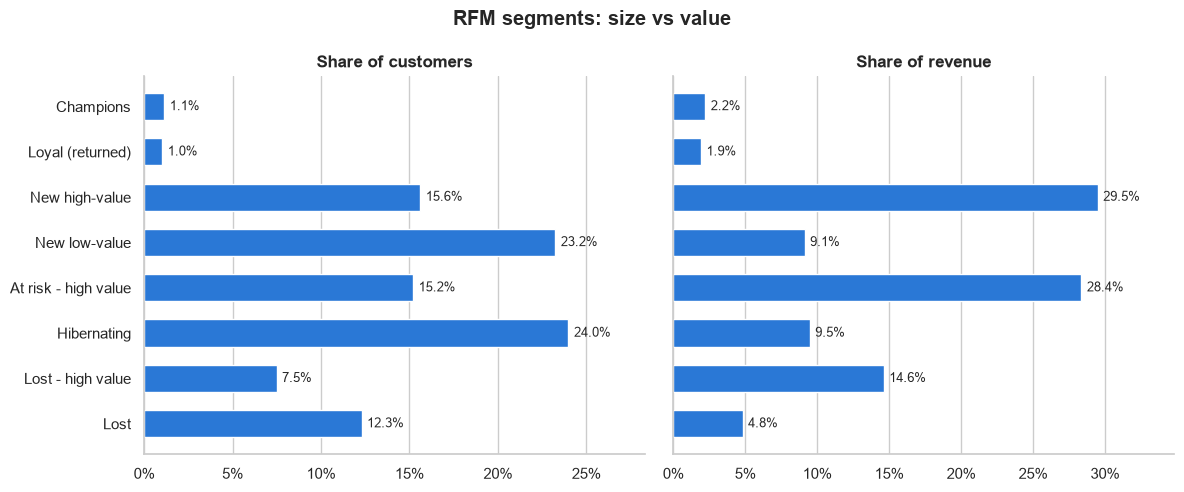

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["axes.titleweight"] = "bold"
BLUE = "#2a78d6"
IMG_DIR = Path("../images")

plot = seg.iloc[::-1]   # first segment at the top
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, col, title in [(ax1, "customers_%", "Share of customers"),
                       (ax2, "revenue_%", "Share of revenue")]:
    bars = ax.barh(plot.index, plot[col], color=BLUE, height=0.6)
    for b in bars:
        ax.annotate(f"{b.get_width():.1f}%", (b.get_width(), b.get_y() + b.get_height() / 2),
                    va="center", fontsize=9, xytext=(4, 0), textcoords="offset points")
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.margins(x=0.18)
    ax.grid(axis="y", visible=False)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("RFM segments: size vs value", fontweight="bold")
fig.tight_layout()
fig.savefig(IMG_DIR / "07_rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight - value sits in one-time high spenders, not in loyal customers**

- All reference checks pass (93,350 customers, 96,470 orders, 13,220,248.93 revenue). Customers with 2+ separate purchase days: **2,015 (2.2%)**, vs 2,801 when counting orders.
- **97.8%** of customers have F = 1, which confirms that Frequency cannot be split into quintiles.
- Returned customers (**Champions + Loyal**) are only **2.2%** of customers and **4.1%** of revenue. They spend ~270 BRL on average, about 5x a low-value customer (~55 BRL).
- The money is in **one-time high spenders** (M = 4-5, above ~110 BRL):
  - **New high-value**: 15.6% of customers -> **29.5%** of revenue (last purchase within ~6 months).
  - **At risk - high value**: 15.2% of customers -> **28.4%** of revenue (last purchase 6-12 months ago).
  - **Lost - high value**: 7.5% of customers -> 14.6% of revenue (more than a year ago).
- Together these three groups are **38%** of customers but **73%** of revenue.

**Business meaning / actions:**
1. **New high-value** (14,577 customers) is the top priority: recent, already spent a lot, and still inside the typical 2-3 month return window (median 76 days, section 5 of the EDA). Target them with a second-purchase offer.
2. **At risk - high value** (14,198) need a win-back campaign before they become lost.
3. Low-value groups (New low-value, Hibernating, Lost) are ~60% of customers but only ~23% of revenue: low-cost, automated contact only.


## 5. K-Means clustering

Section 4 built segments from **rules we chose**. Here an algorithm finds groups **from the data itself**, and then we compare the two.

**Feature choices (and why):**
- **Recency (days)**: used as is.
- **Monetary**: `log1p` transform first. Spend is very skewed (skewness 9.9 in the EDA); without the log, a few big spenders would pull whole clusters towards them.
- **Frequency is NOT used in the distance.** 97.8% of customers have the same value (1), so after scaling the few repeat buyers become extreme points that distort the clusters. We use it afterwards to **describe** each cluster (share of returning customers).
- **StandardScaler**: puts both features on the same scale (mean 0, std 1). K-Means uses distances, so without it the feature with bigger numbers (recency in days) would dominate.


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = pd.DataFrame({
    "recency_days": rfm["recency_days"],
    "log_monetary": np.log1p(rfm["monetary"]),
}, index=rfm.index)

scaler = StandardScaler()
X = scaler.fit_transform(features)
print("Scaled features -> mean:", X.mean(axis=0).round(2), "| std:", X.std(axis=0).round(2))

Scaled features -> mean: [-0.  0.] | std: [1. 1.]


### 5.1 How many clusters? (Elbow + Silhouette)

- **Elbow (inertia)**: total distance of customers to their cluster centre. It always falls when k grows; we look for the point where the drop slows down (the "elbow").
- **Silhouette** (-1 to 1): how well each customer fits its own cluster compared with the nearest other cluster. Higher = better separated.
- Silhouette needs the distance between every pair of points (93,350² pairs = too slow), so it is computed on a **random sample of 10,000 customers**.


      inertia  silhouette
k                        
2  121011.141       0.347
3   79051.765       0.358
4   62869.747       0.334
5   51389.741       0.331
6   42117.086       0.347
7   36936.527       0.339
8   32876.226       0.330


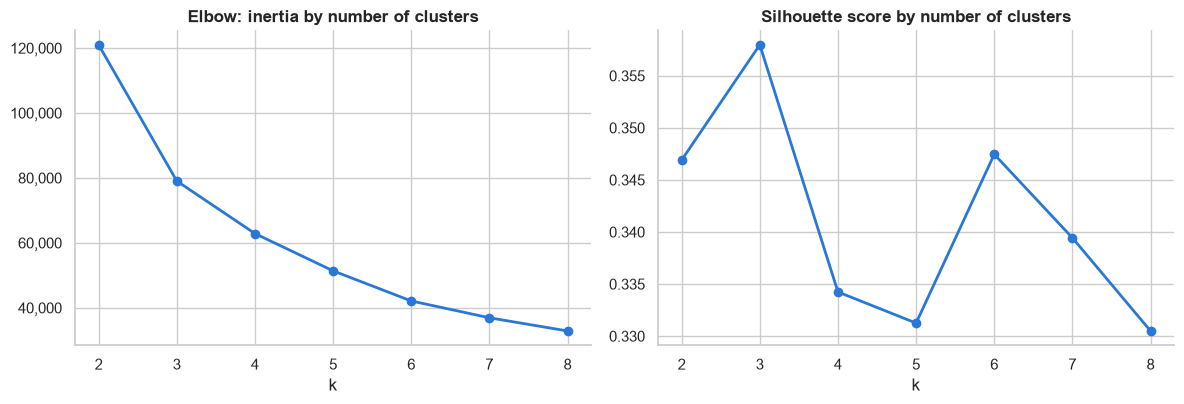

In [8]:
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sil = silhouette_score(X, km.labels_, sample_size=10_000, random_state=42)
    results.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
k_tbl = pd.DataFrame(results).set_index("k")
print(k_tbl.round(3).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(k_tbl.index, k_tbl["inertia"], color=BLUE, lw=2, marker="o")
ax1.set_title("Elbow: inertia by number of clusters")
ax1.set_xlabel("k")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax2.plot(k_tbl.index, k_tbl["silhouette"], color=BLUE, lw=2, marker="o")
ax2.set_title("Silhouette score by number of clusters")
ax2.set_xlabel("k")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "08_kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Final model and cluster profiles

`K` is set below. Besides the two metrics, the business needs a number of groups that a marketing team can actually act on (usually 3-6).
Clusters are renumbered from highest to lowest median spend, so the numbering is stable between runs.


In [9]:
K = 4   # chosen from the Elbow + Silhouette results above

km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
rfm["cluster_raw"] = km.labels_

# Stable numbering: cluster 0 = highest median spend
order = (rfm.groupby("cluster_raw")["monetary"].median()
            .sort_values(ascending=False).index)
rfm["cluster"] = rfm["cluster_raw"].map({old: new for new, old in enumerate(order)})

profile = (rfm.groupby("cluster")
              .agg(customers=("monetary", "size"),
                   revenue=("monetary", "sum"),
                   median_recency_days=("recency_days", "median"),
                   median_spend=("monetary", "median"),
                   returners_pct=("frequency", lambda s: (s >= 2).mean() * 100)))
profile["customers_%"] = profile["customers"] / profile["customers"].sum() * 100
profile["revenue_%"] = profile["revenue"] / profile["revenue"].sum() * 100

# Automatic names from the medians (refined by hand after reading the results)
rec_cut, spend_cut = rfm["recency_days"].median(), rfm["monetary"].median()
def name_cluster(row):
    when = "Recent" if row["median_recency_days"] < rec_cut else "Inactive"
    value = "high spenders" if row["median_spend"] > spend_cut else "low spenders"
    return f"{when} {value}"
profile["name"] = profile.apply(name_cluster, axis=1)
dup = profile["name"].duplicated(keep=False)
profile.loc[dup, "name"] = profile.loc[dup, "name"] + " (" + profile.index[dup].astype(str) + ")"
rfm["cluster_name"] = rfm["cluster"].map(profile["name"])

print(f"Overall medians -> recency: {rec_cut:.0f} days | spend: {spend_cut:.1f} BRL\n")
print(profile[["name", "customers", "customers_%", "revenue_%", "median_recency_days",
               "median_spend", "returners_pct"]].round(1).to_string())

Overall medians -> recency: 220 days | spend: 89.7 BRL

                           name  customers  customers_%  revenue_%  median_recency_days  median_spend  returners_pct
cluster                                                                                                             
0        Inactive high spenders      18198         19.5       35.0                373.0         168.9            2.9
1          Recent high spenders      28504         30.5       48.3                130.0         149.9            4.3
2         Inactive low spenders      21118         22.6        8.0                377.0          49.9            0.5
3           Recent low spenders      25530         27.3        8.7                130.0          44.9            0.6


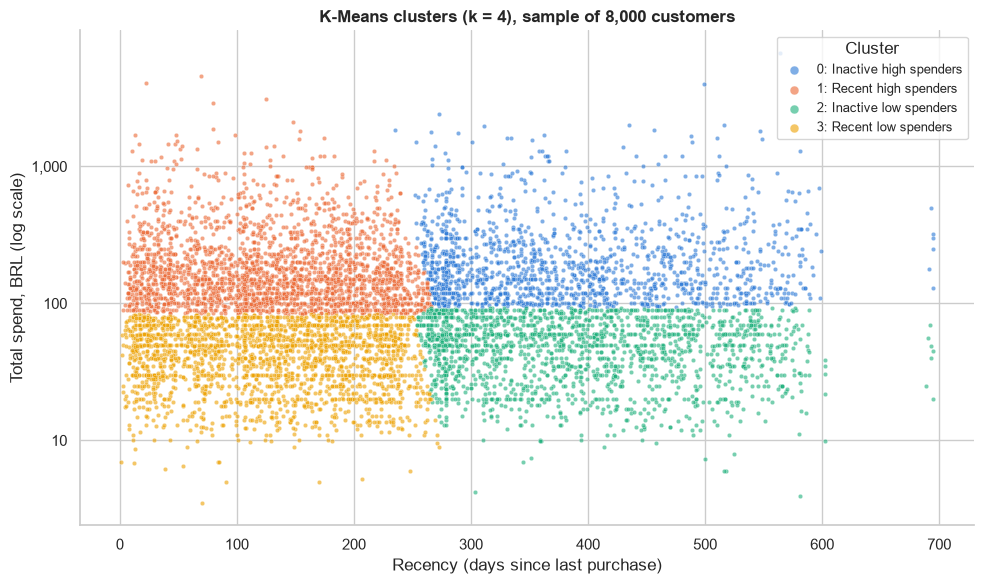

In [10]:
# Scatter of a random sample (93k points would hide each other)
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
sample = rfm.sample(8_000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))
for c in sorted(rfm["cluster"].unique()):
    pts = sample[sample["cluster"] == c]
    ax.scatter(pts["recency_days"], pts["monetary"], s=10, alpha=0.6,
               color=CLUSTER_COLORS[c], edgecolors="white", linewidths=0.3,
               label=f"{c}: {profile.loc[c, 'name']}")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Recency (days since last purchase)")
ax.set_ylabel("Total spend, BRL (log scale)")
ax.set_title(f"K-Means clusters (k = {K}), sample of 8,000 customers")
ax.legend(title="Cluster", loc="upper right", fontsize=9, markerscale=2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "09_kmeans_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Do the algorithm and the rules agree?

Each row is a rule-based segment (section 4); the columns show how its customers are spread over the K-Means clusters (% of the row).


In [11]:
agree = pd.crosstab(rfm["segment"], rfm["cluster_name"], normalize="index") * 100
agree = agree.reindex(SEGMENT_ORDER)
print(agree.round(1).to_string())

cluster_name          Inactive high spenders  Inactive low spenders  Recent high spenders  Recent low spenders
segment                                                                                                       
Champions                                0.0                    0.0                  87.7                 12.3
Loyal (returned)                        54.5                   11.9                  30.4                  3.1
New high-value                           0.0                    0.0                 100.0                  0.0
New low-value                            0.0                    0.0                  19.4                 80.6
At risk - high value                    55.8                    0.0                  44.2                  0.0
Hibernating                              6.1                   48.8                   9.9                 35.2
Lost - high value                      100.0                    0.0                   0.0                  0.0
L

**Insight - K-Means confirms what matters, but finds no natural customer groups**

- **Silhouette is low for every k (0.33-0.36).** The best is k = 3 (0.358), but the differences between k values are tiny. The Elbow curve has no sharp bend after k = 3. Honest reading: the customers form **one continuous cloud**, not separate natural groups.
- The scatter plot shows it clearly: with k = 4, K-Means simply **cuts the cloud into four quadrants**, at about **265 days** of recency and **~90 BRL** of spend (close to the overall medians: 220 days, 89.7 BRL).
- We keep **k = 4**: its silhouette (0.334) is almost the same as k = 3, and four quadrants (recent/inactive x high/low spend) are easy for a marketing team to act on.
- The value is again in high spenders: **Recent high spenders** = 30.5% of customers -> **48.3%** of revenue; **Inactive high spenders** = 19.5% -> **35.0%**. Together: half the customers, **83%** of revenue.
- Returning customers are rare in every cluster (at most 4.3%), so K-Means **cannot isolate loyal customers**; only the rules (F >= 2) can.
- **Agreement with the rules is strong:** New high-value -> 100% Recent high spenders; Lost - high value -> 100% Inactive high spenders; Lost -> 88% Inactive low spenders; Champions -> 88% Recent high spenders. The only splits (At risk - high value, Hibernating) come from the different recency cut (rules: 178 days, K-Means: ~265 days).

**Decision:** the **rule-based segments (section 4)** are the main segmentation for the dashboard and recommendations: they are explainable, they separate returning customers, and K-Means independently confirmed that **recency and spend** are the two dimensions that split this customer base. The K-Means cluster is kept as an extra column.


## 6. Export to SQL Server for Power BI

One row per customer goes to the table **`ml.CustomerSegments`** (new schema `ml` = results produced by Python/ML).
Power BI will read it through a view joined with `dw.DimCustomer` (see `sql/08_ml_views.sql`), so every number on the dashboard stays checkable with SQL.


In [12]:
from db_utils import write_table, run_query

export = (rfm.reset_index()[["customer_key", "customer_unique_id", "first_purchase", "last_purchase",
                             "recency_days", "frequency", "orders", "monetary",
                             "R", "F", "M", "RFM_code", "segment", "cluster", "cluster_name"]]
             .rename(columns={"frequency": "purchase_days"}))
export["snapshot_date"] = SNAPSHOT

n = write_table(export, "CustomerSegments")

# Read back from SQL Server and compare with the reference numbers
back = run_query("SELECT COUNT(*) AS customers, ROUND(SUM(monetary), 2) AS revenue, "
                 "COUNT(DISTINCT customer_key) AS unique_keys FROM ml.CustomerSegments")
print(back.to_string(index=False), "\n")
print(f"{'OK' if n == 93_350 else 'MISMATCH'}  rows written: {n:,}")
print(f"{'OK' if back['unique_keys'].iloc[0] == 93_350 else 'MISMATCH'}  one row per customer")
print(f"{'OK' if round(back['revenue'].iloc[0], 2) == 13_220_248.93 else 'MISMATCH'}  revenue: {back['revenue'].iloc[0]:,.2f}")

 customers     revenue  unique_keys
     93350 13220248.93        93350 

OK  rows written: 93,350
OK  one row per customer
OK  revenue: 13,220,248.93
